# Operaciones de aprendizaje automático (TC5061 Gpo 10)

- Semana 3
- Exploración de datos (EDA). El entrenamiento se migró a train.py
- Jesús Carrillo Cantú - A01840421

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# 1. Dataset

**IBM HR Analytics Employee Attrition & Performance**
- Fuente: https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset
- Registros: 1,470 empleados
- Variables: 35
- Target: Attrition (binaria)
  - 0 = El empleado NO abandonó la empresa
  - 1 = El empleado SI abandonó la empresa

**Escalas de las variables ordinales:**

| Variable | Escala |
|---|---|
| Education | 1 Below College, 2 College, 3 Bachelor, 4 Master, 5 Doctor |
| EnvironmentSatisfaction, JobSatisfaction, RelationshipSatisfaction, JobInvolvement | 1 Low, 2 Medium, 3 High, 4 Very High |
| PerformanceRating | 1 Low, 2 Good, 3 Excellent, 4 Outstanding |
| WorkLifeBalance | 1 Bad, 2 Good, 3 Better, 4 Best |


In [3]:
path = '../data/WA_Fn-UseC_-HR-Employee-Attrition.csv'
original_df = pd.read_csv(path)

# 2. EDA inicial

**Estructura**
- 1,470 registros y 35 variables
- 26 variables numéricas
- 9 variables de texto
- No hay valores nulos

**Variable target**
- Variable: Attrition
- Desbalanceada
- 1,233 empleados permanecieron (83.9%)
- 237 abandonaron (16.1%)

**Variables categóricas**
- Distribución desigual entre categorías.
- Ejemplos muchos registros:
  - Travel_Rarely en `BusinessTravel` (71.0%)
  - Research & Development en `Department` (65.4%)
  - Life Sciences en `EducationField` (41.2%)
- Ejemplos pocos registros:
  - Human Resources en `Department` (63, 4.3%)
  - Human Resources en `EducationField` (27, 1.8%)

**Variables numéricas**
- `MonthlyIncome`, `TotalWorkingYears` y las variables de antigüedad (`Years*`) tienen sesgo a la derecha.
- `DailyRate`, `HourlyRate` y `MonthlyRate` tienen distribución prácticamente uniforme.

**Columnas sin valor para el modelo**
- `EmployeeNumber`: identificador único de cada empleado, sin valor predictivo.
- `Over18`: todos los registros tienen el valor Y.
- `StandardHours` y `EmployeeCount`: Desviación estándar 0, es decir tienen un valor constante.

In [4]:
print("Tamaño del dataframe:", original_df.shape)
original_df.describe(include = 'all').T

Tamaño del dataframe: (1470, 35)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1470,2,No,1233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1470.0,NaN,NaN,NaN,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0


In [5]:
original_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [6]:
# Guardar variables categóricas y numéricas
cat_cols = original_df.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = original_df.select_dtypes(include=np.number).columns.tolist()

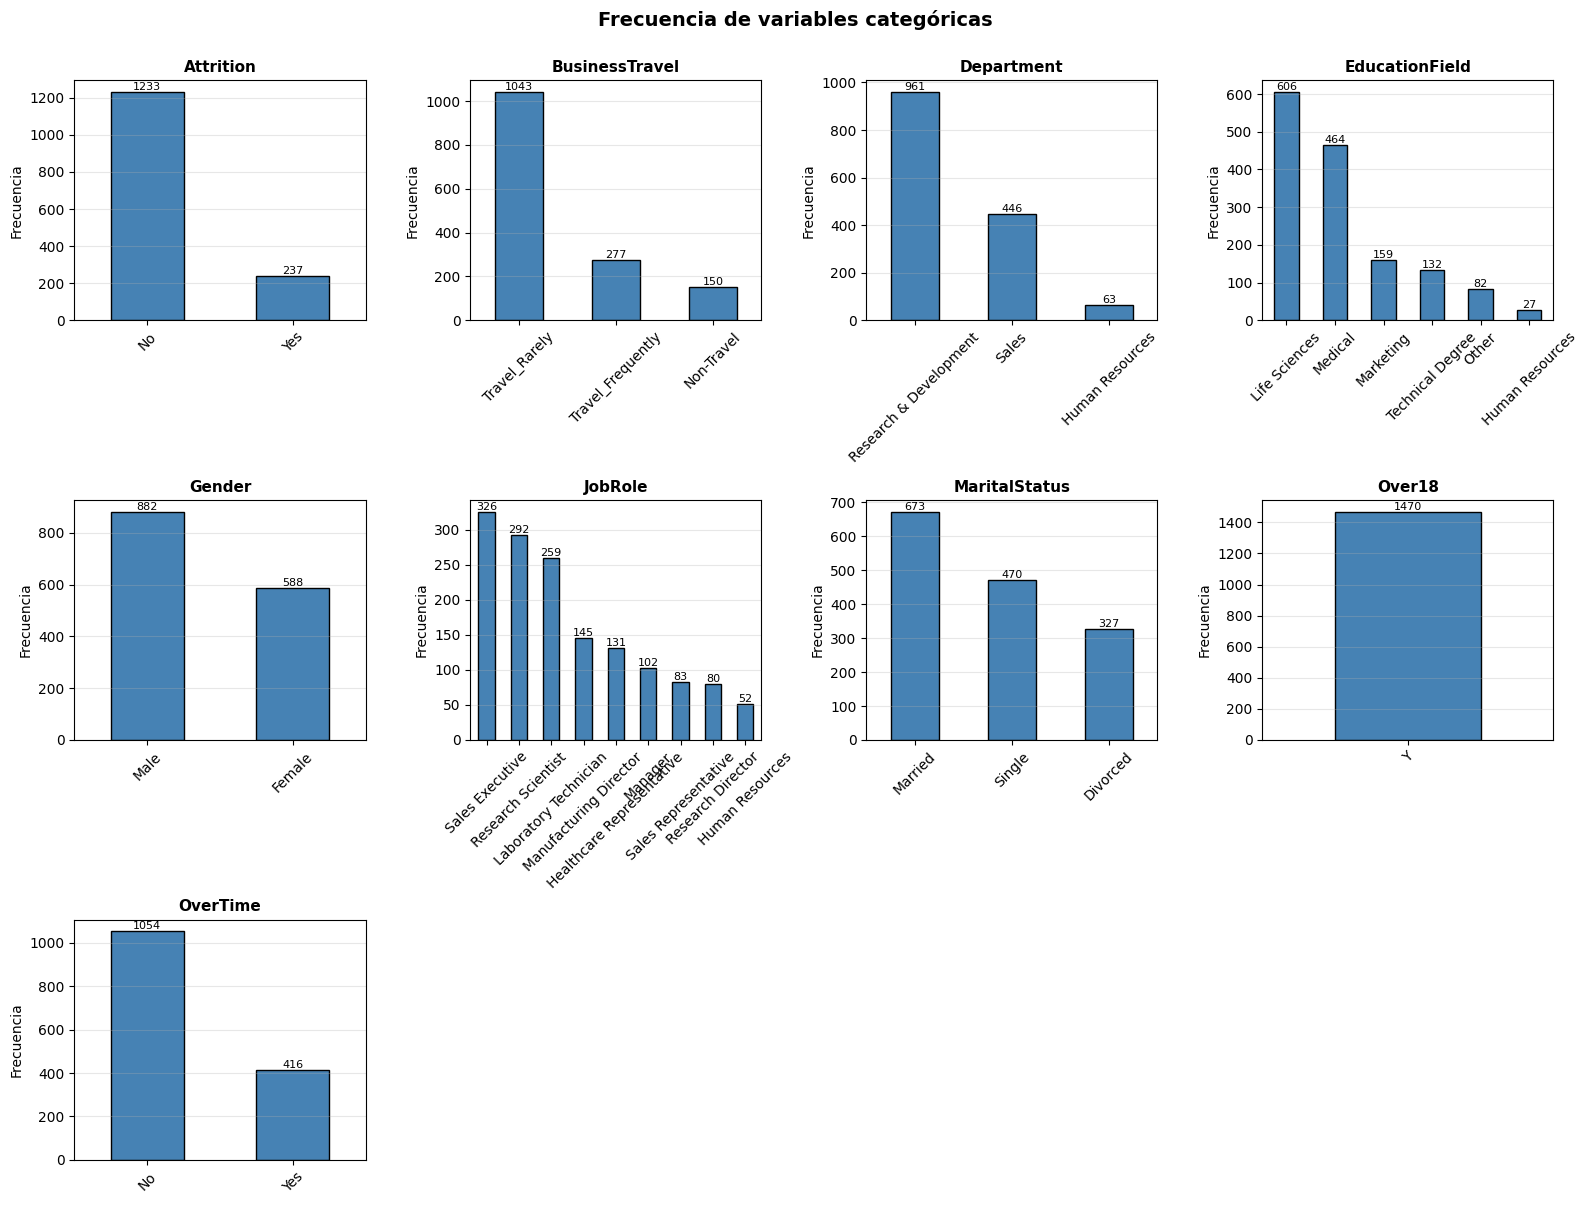

In [7]:
# Análisis variables categóricas

n_cat = len(cat_cols)
n_cols = 4
n_rows = int(np.ceil(n_cat / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.ravel()

for col, ax in zip(cat_cols, axes):
    data = original_df[col].value_counts()
    title = col

    # Crear gráfica de barras
    data.plot(kind='bar', ax=ax, color='steelblue', edgecolor='black')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Frecuencia')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=0.3)

    for i, v in enumerate(data.values):
        ax.text(i, v, str(v), ha='center', va='bottom', fontsize=8)

# Ocultar subplots sobrantes
for idx in range(len(cat_cols), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Frecuencia de variables categóricas', fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

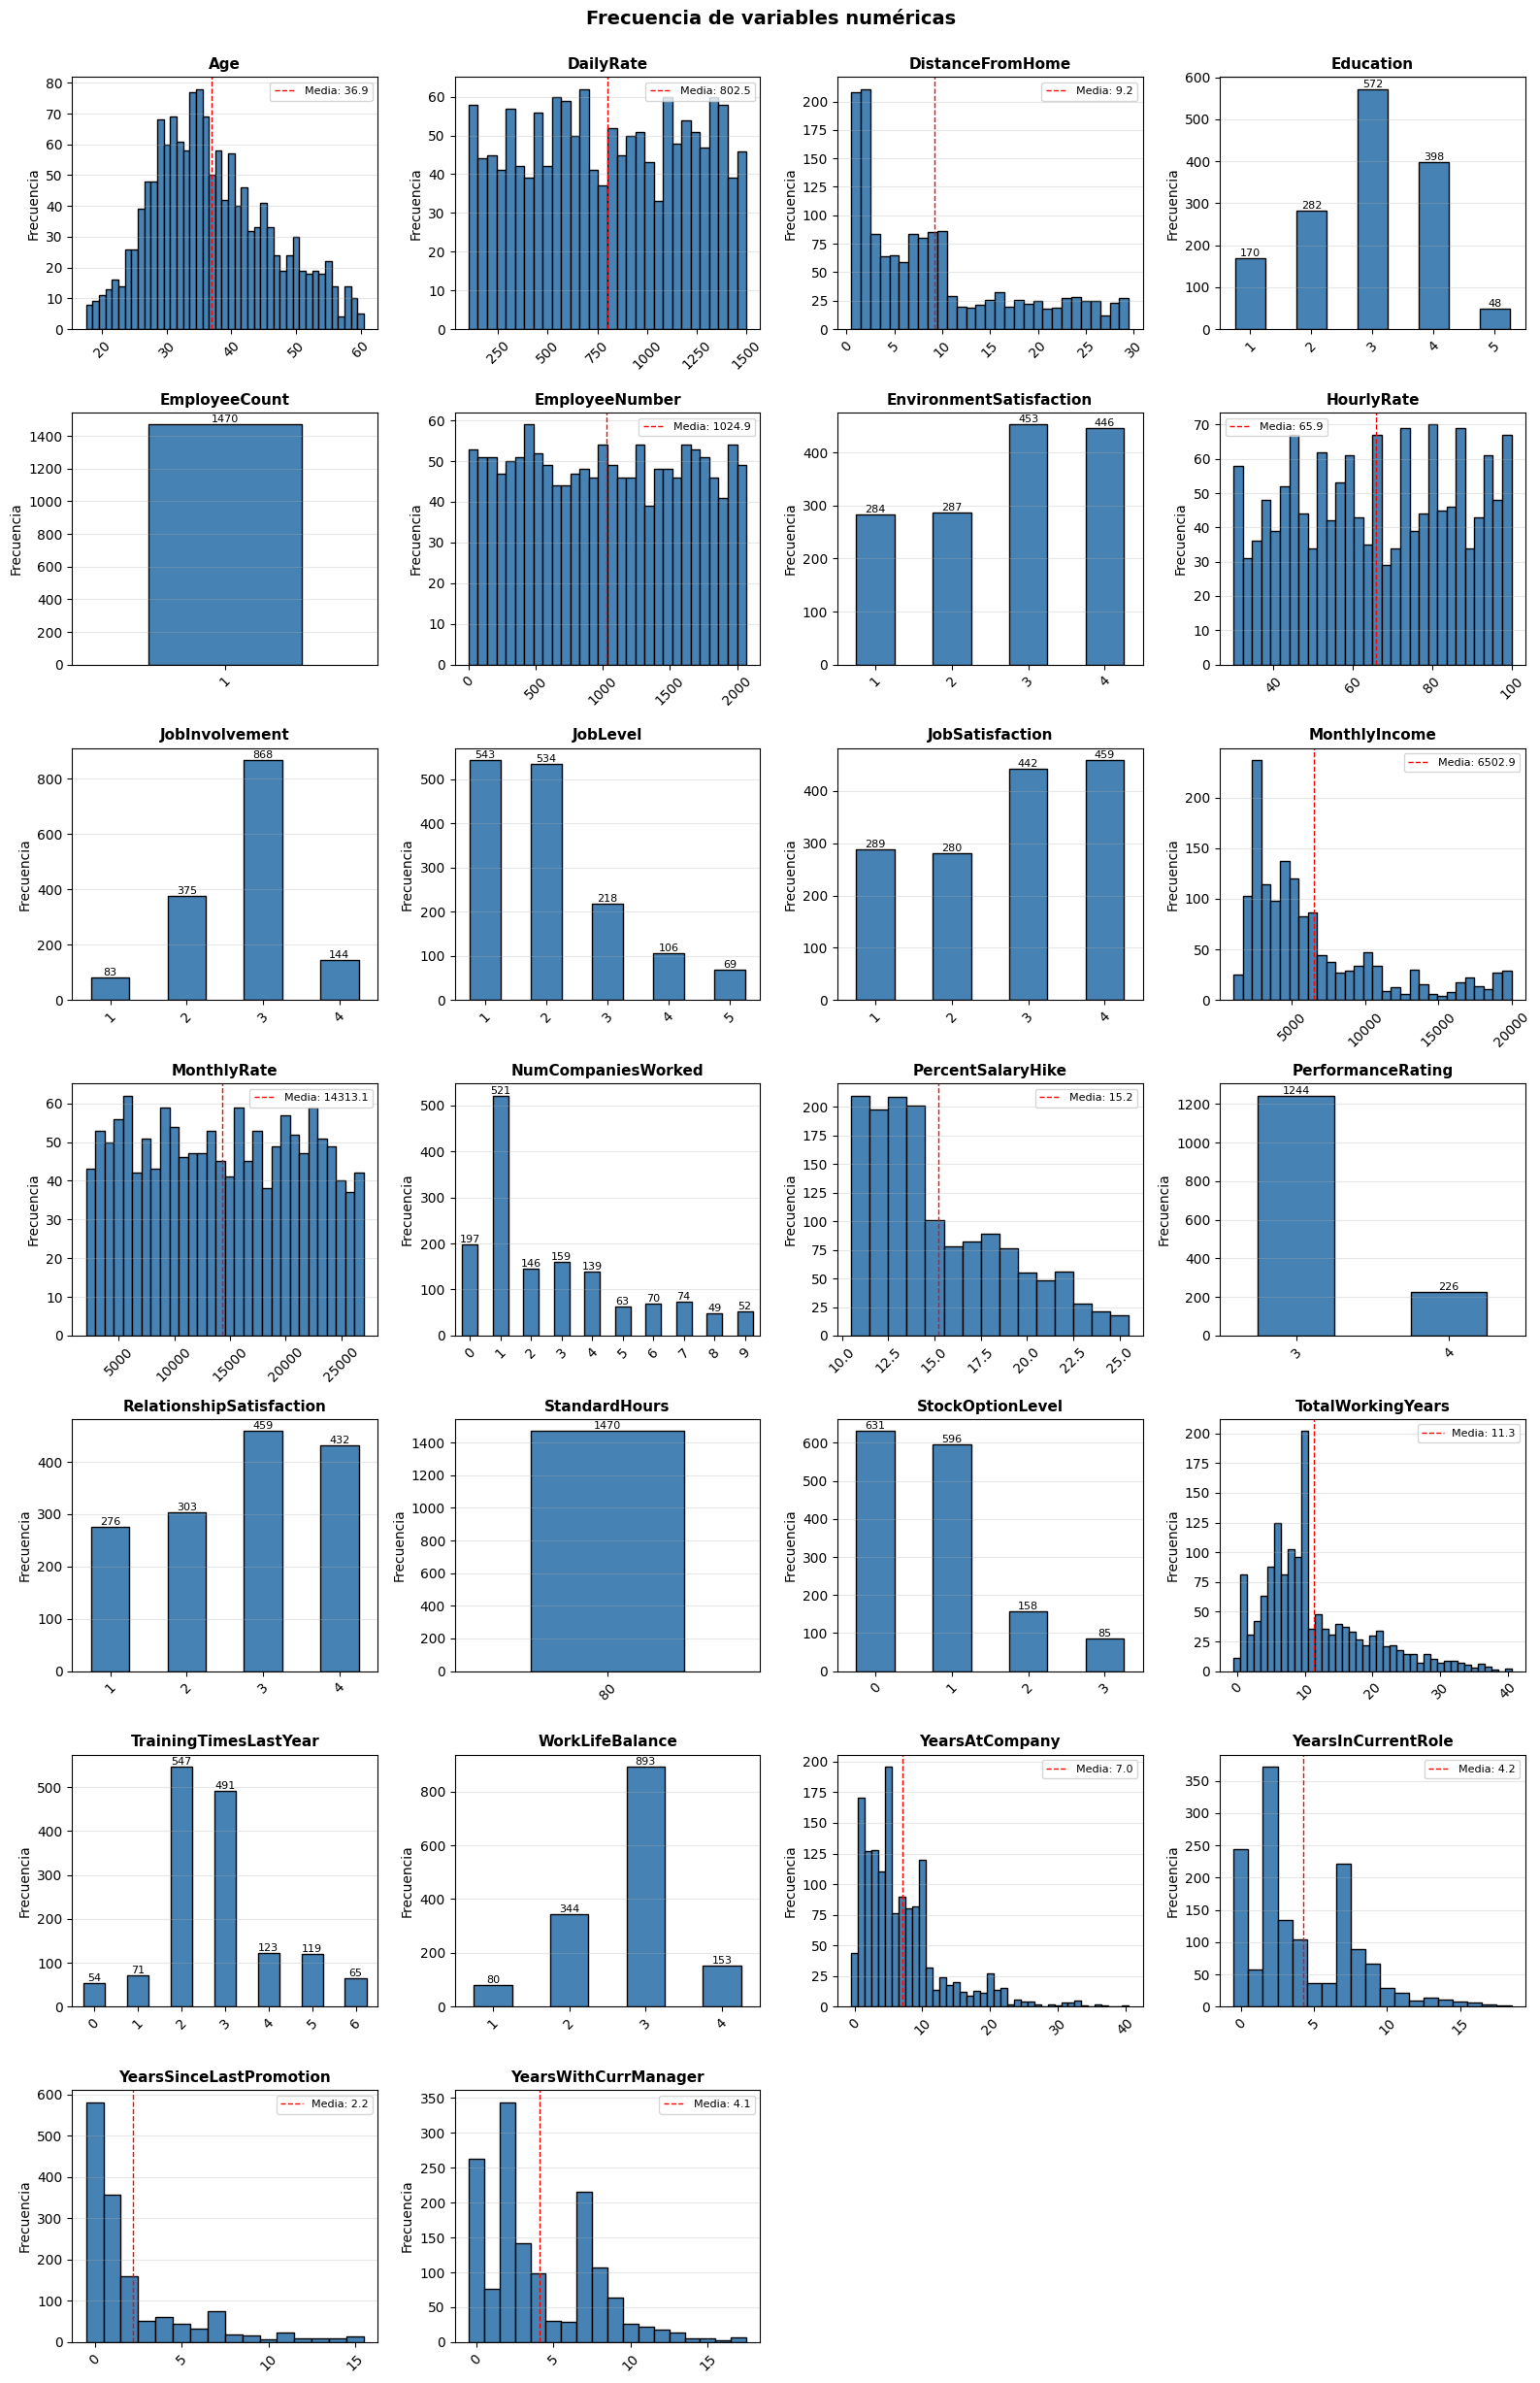

In [8]:
# Análisis variables numéricas

n_num = len(num_cols)
n_cols = 4
n_rows = int(np.ceil(n_num / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.5 * n_rows))
axes = axes.ravel()

for col, ax in zip(num_cols, axes):
    # Mostrar gráfica de barras para pocos valores únicos (<=10)
    # Mostrar histrograma para muchos valores únicos (> 10)
    if original_df[col].nunique() <= 10:
        data = original_df[col].value_counts().sort_index()
        data.plot(kind='bar', ax=ax, color='steelblue', edgecolor='black')
        ax.set_ylabel('Frecuencia')
        for i, v in enumerate(data.values):
            ax.text(i, v, str(v), ha='center', va='bottom', fontsize=8)
    else:
        values = original_df[col].dropna()
        span = values.max() - values.min() + 1
        bins = np.arange(values.min(), values.max() + 2) - 0.5 if span <= 50 else 30

        ax.hist(values, bins=bins, color='steelblue', edgecolor='black')
        ax.set_ylabel('Frecuencia')

        mean_value = original_df[col].mean()
        ax.axvline(mean_value, color='red', linestyle='--', linewidth=1,
                   label=f'Media: {mean_value:.1f}')
        ax.legend(fontsize=8)

    ax.set_title(col, fontsize=11, fontweight='bold')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=0.3)

# Ocultar subplots sobrantes
for idx in range(len(num_cols), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Frecuencia de variables numéricas', fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

# 3. Data cleaning
**Valores faltantes**
- Ninguna columna tiene nulos
- No se aplica imputación

**Duplicados**
- No hay registros duplicados
- No se elimina ningún registro

**Tipos de datos**
- 6 columnas enteras y 9 de texto, consistentes con su contenido. Las variables ordinales están almacenadas como enteros, lo cual es correcto.
- No se corrige ningún tipo

**Columnas sin valor**
- `EmployeeNumber` es un identificador, `Over18`, `StandardHours` y `EmployeeCount` tienen un valor constante
- Se eliminan

**Outliers**
- No se analizan en esta etapa. Se analizarán después de la partición, solo con el conjunto de train.

In [9]:
# Valores faltantes, duplicados y tipos de datos
print('Valores nulos totales:', original_df.isnull().sum().sum())
print('Registros duplicados:', original_df.duplicated().sum())
print('Duplicados ignorando EmployeeNumber:',
      original_df.drop(columns='EmployeeNumber').duplicated().sum())
print()
print(original_df.dtypes.value_counts())

Valores nulos totales: 0
Registros duplicados: 0
Duplicados ignorando EmployeeNumber: 0

int64     26
object     9
Name: count, dtype: int64


In [10]:
# Eliminar variables
df = original_df.drop(columns=['Over18', 'StandardHours', 'EmployeeCount', 'EmployeeNumber'])

print("Tamaño del dataframe original:", original_df.shape)
print("Tamaño del nuevo dataframe:", df.shape)

Tamaño del dataframe original: (1470, 35)
Tamaño del nuevo dataframe: (1470, 31)


# 4. Partición train / validation / test

In [11]:
print("Dimensiones y Porcentajes de la partición Train+Validation+Test generada:")
print("-"*75)

X = df.drop(columns='Attrition')
y = df[['Attrition']]

Xtrain, Xtv, ytrain, ytv = train_test_split(X, y, train_size=0.70, stratify=y, random_state=17)
Xval, Xtest, yval, ytest = train_test_split(Xtv, ytv, test_size=0.5, stratify=ytv, random_state=17)

print("Variables de entrada Train, Validation, Test:")
print(Xtrain.shape, '%.1f%%' % (100.*Xtrain.shape[0]/X.shape[0]))
print(Xval.shape, '%.1f%%' % (100.*Xval.shape[0]/X.shape[0])),
print(Xtest.shape, '%.1f%%' % (100.*Xtest.shape[0]/X.shape[0]))

print("\nVariables de salida Train, Validation, Test:")
print(ytrain.shape)
print(yval.shape)
print(ytest.shape)

Dimensiones y Porcentajes de la partición Train+Validation+Test generada:
---------------------------------------------------------------------------
Variables de entrada Train, Validation, Test:
(1029, 30) 70.0%
(220, 30) 15.0%
(221, 30) 15.0%

Variables de salida Train, Validation, Test:
(1029, 1)
(220, 1)
(221, 1)


In [12]:
# Codificación de la variable target (Attrition)

le = LabelEncoder()

ytrainT = pd.DataFrame(
    le.fit_transform(ytrain.values.ravel()),
    columns=['Attrition'],
    index=ytrain.index
)

yvalT = pd.DataFrame(
    le.transform(yval.values.ravel()),
    columns=['Attrition'],
    index=yval.index
)

ytestT = pd.DataFrame(
    le.transform(ytest.values.ravel()),
    columns=['Attrition'],
    index=ytest.index
)

# 5. EDA: Train

**Variable target (Attrition)**
- 16.1% de los empleados en train abandonó la empresa (Attrition Yes).
- Un modelo que siempre predice "No abandona/Attrition No" tendría 83.9% de accuracy, por lo que esa métrica no es suficiente para evaluar los modelos.

**Distribuciones**
- Asimetría positiva en `YearsSinceLastPromotion` (2.04), `YearsAtCompany` (1.81), `MonthlyIncome` (1.39), `TotalWorkingYears` (1.16) y `NumCompaniesWorked` (1.08).
- `Age`, `DailyRate`, `HourlyRate` y `MonthlyRate` son aproximadamente simétricas.

**Outliers**
- 10 variables con outliers.
- De las cuales 7 variables son outliers verdaderos:
  - `MonthlyIncome`, `TotalWorkingYears`, `YearsAtCompany`, `YearsInCurrentRole`, `YearsSinceLastPromotion`, `YearsWithCurrManager` y `NumCompaniesWorked`
- De las cuales 3 variables son falso positivo de outliers:
  - `PerformanceRating`, `StockOptionLevel`, `TrainingTimesLastYear`
  - Esas 3 variables son categóricas con una escala muy corta.
  - Sus extremos corresponden a un porcentaje considerable de los datos, no son valores extremos atípicos.
- Por lo tanto, se mantienen los outliers.

**Multicolinealidad**
- 7 pares con correlación mayor a 0.7:
  - `JobLevel` y `MonthlyIncome` (0.95)
  - `JobLevel` y `TotalWorkingYears` (0.77)
  - `MonthlyIncome` y `TotalWorkingYears` (0.76)
  - `PercentSalaryHike` y `PerformanceRating` (0.76)
  - `YearsAtCompany` y `YearsInCurrentRole` (0.76)
  - `YearsAtCompany` y `YearsWithCurrManager` (0.76)
  - `YearsInCurrentRole` y `YearsWithCurrManager` (0.73)

**Relación con Attrition: variables categóricas**

Estos son los valores por variable categórica que tienden a abandonar la empresa:
- `OverTime`: Yes
- `MaritalStatus`: Single
- `BusinessTravel`: Travel_Frequently
- `JobRole`: Sales Representative
- `Department`: Sales y Human Resources
- `EducationField`: Marketing, Human Resources y Technical Degree

**Relación con Attrition: variables numéricas**

Estos son los valores por variable numérica que tienden a abandonar la empresa:
- `MonthlyIncome`: Menor ingreso
- `JobLevel`: Menor nivel de puesto
- `Age`: Los más jóvenes
- `DistanceFromHome`: Mayor distancia entre el trabajo y su casa
- `EnvironmentSatisfaction`: Menor satisfacción en el ambiente laboral
- `JobSatisfaction`: Menor satisfacción en su puesto
- `TotalWorkingYears`, `YearsAtCompany`, `YearsInCurrentRole`, `YearsWithCurrManager`: A menor antigüedad mayor tendencia a abandonar la empresa

**Implicaciones para el modelado**
- Usar métricas adecuadas al desbalance (recall, F1, PR-AUC) y validación cruzada estratificada.
- Evaluar transformaciones que reduzcan la asimetría de las variables numéricas.
- Preferir modelos con regularización por la multicolinealidad.
- `Gender`, `HourlyRate` y `MonthlyRate` no muestran diferencia entre clases, son candidatas a eliminarse en iteraciones posteriores.

In [13]:
print('Porcentaje de datos en cada clase del conjunto de entrenamiento (Train):\n', ytrainT['Attrition'].value_counts() / ytrainT.shape[0])

Porcentaje de datos en cada clase del conjunto de entrenamiento (Train):
 Attrition
0    0.838678
1    0.161322
Name: count, dtype: float64


In [14]:
# Descriptivos variables numéricas

num_cols_Xtrain = Xtrain.select_dtypes(include=np.number).columns.tolist()
cat_cols_Xtrain = Xtrain.select_dtypes(include=['object', 'category']).columns.tolist()

desc_num = Xtrain[num_cols_Xtrain].describe().T
desc_num['skewness'] = Xtrain[num_cols_Xtrain].skew()
desc_num['kurtosis'] = Xtrain[num_cols_Xtrain].kurtosis()
desc_num['cv'] = desc_num['std'] / desc_num['mean'].abs()
desc_num['range'] = desc_num['max'] - desc_num['min']

print(desc_num.round(2))

                           count      mean      std     min     25%      50%  \
Age                       1029.0     36.84     9.10    18.0    30.0     35.0   
DailyRate                 1029.0    811.58   401.58   102.0   474.0    809.0   
DistanceFromHome          1029.0      9.49     8.25     1.0     2.0      7.0   
Education                 1029.0      2.90     1.02     1.0     2.0      3.0   
EnvironmentSatisfaction   1029.0      2.73     1.09     1.0     2.0      3.0   
HourlyRate                1029.0     66.24    20.41    30.0    49.0     67.0   
JobInvolvement            1029.0      2.74     0.71     1.0     2.0      3.0   
JobLevel                  1029.0      2.07     1.11     1.0     1.0      2.0   
JobSatisfaction           1029.0      2.75     1.11     1.0     2.0      3.0   
MonthlyIncome             1029.0   6519.17  4695.77  1009.0  2974.0   4969.0   
MonthlyRate               1029.0  14191.36  7044.33  2097.0  8018.0  14075.0   
NumCompaniesWorked        1029.0      2.

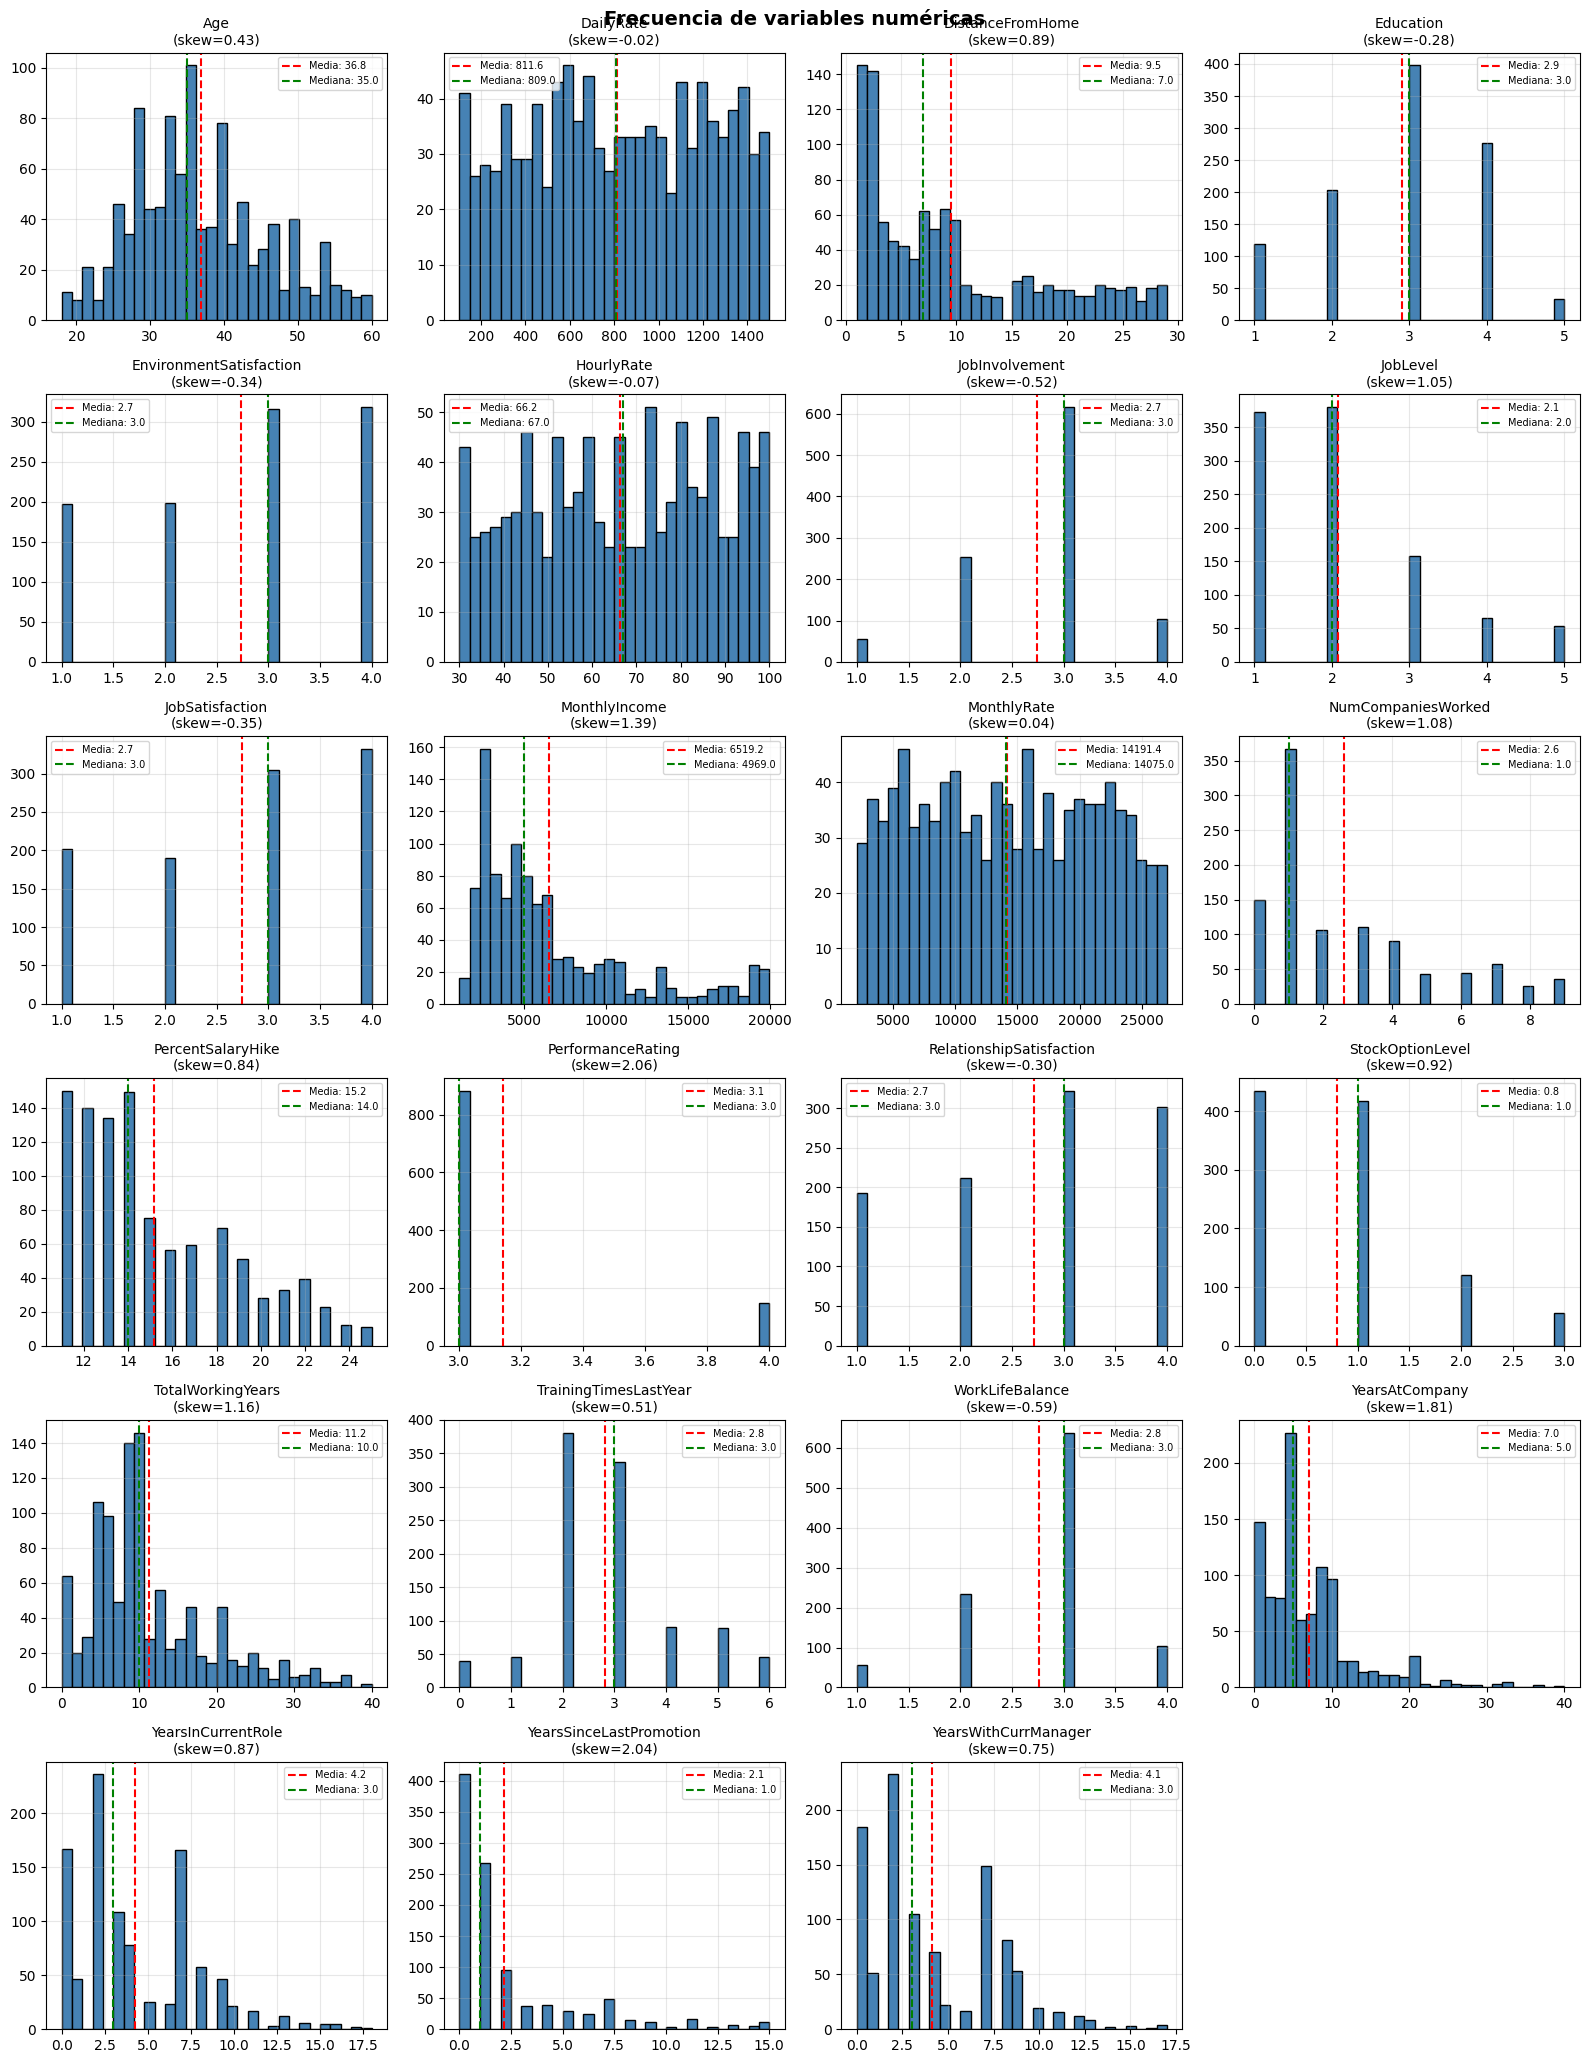

In [15]:
# Distribución variables numéricas

n_num = len(num_cols_Xtrain)
n_cols_plot = 4
n_rows_plot = int(np.ceil(n_num / n_cols_plot))

fig, axes = plt.subplots(n_rows_plot, n_cols_plot, figsize=(16, 3.5 * n_rows_plot))
axes = axes.ravel()

for col, ax in zip(num_cols_Xtrain, axes):
    Xtrain[col].hist(bins=30, ax=ax, color='steelblue', edgecolor='black')
    ax.axvline(Xtrain[col].mean(), color='red', linestyle='--',
               label=f'Media: {Xtrain[col].mean():.1f}')
    ax.axvline(Xtrain[col].median(), color='green', linestyle='--',
               label=f'Mediana: {Xtrain[col].median():.1f}')
    ax.set_title(f'{col}\n(skew={Xtrain[col].skew():.2f})', fontsize=10)
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

for idx in range(len(num_cols_Xtrain), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Frecuencia de variables numéricas', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

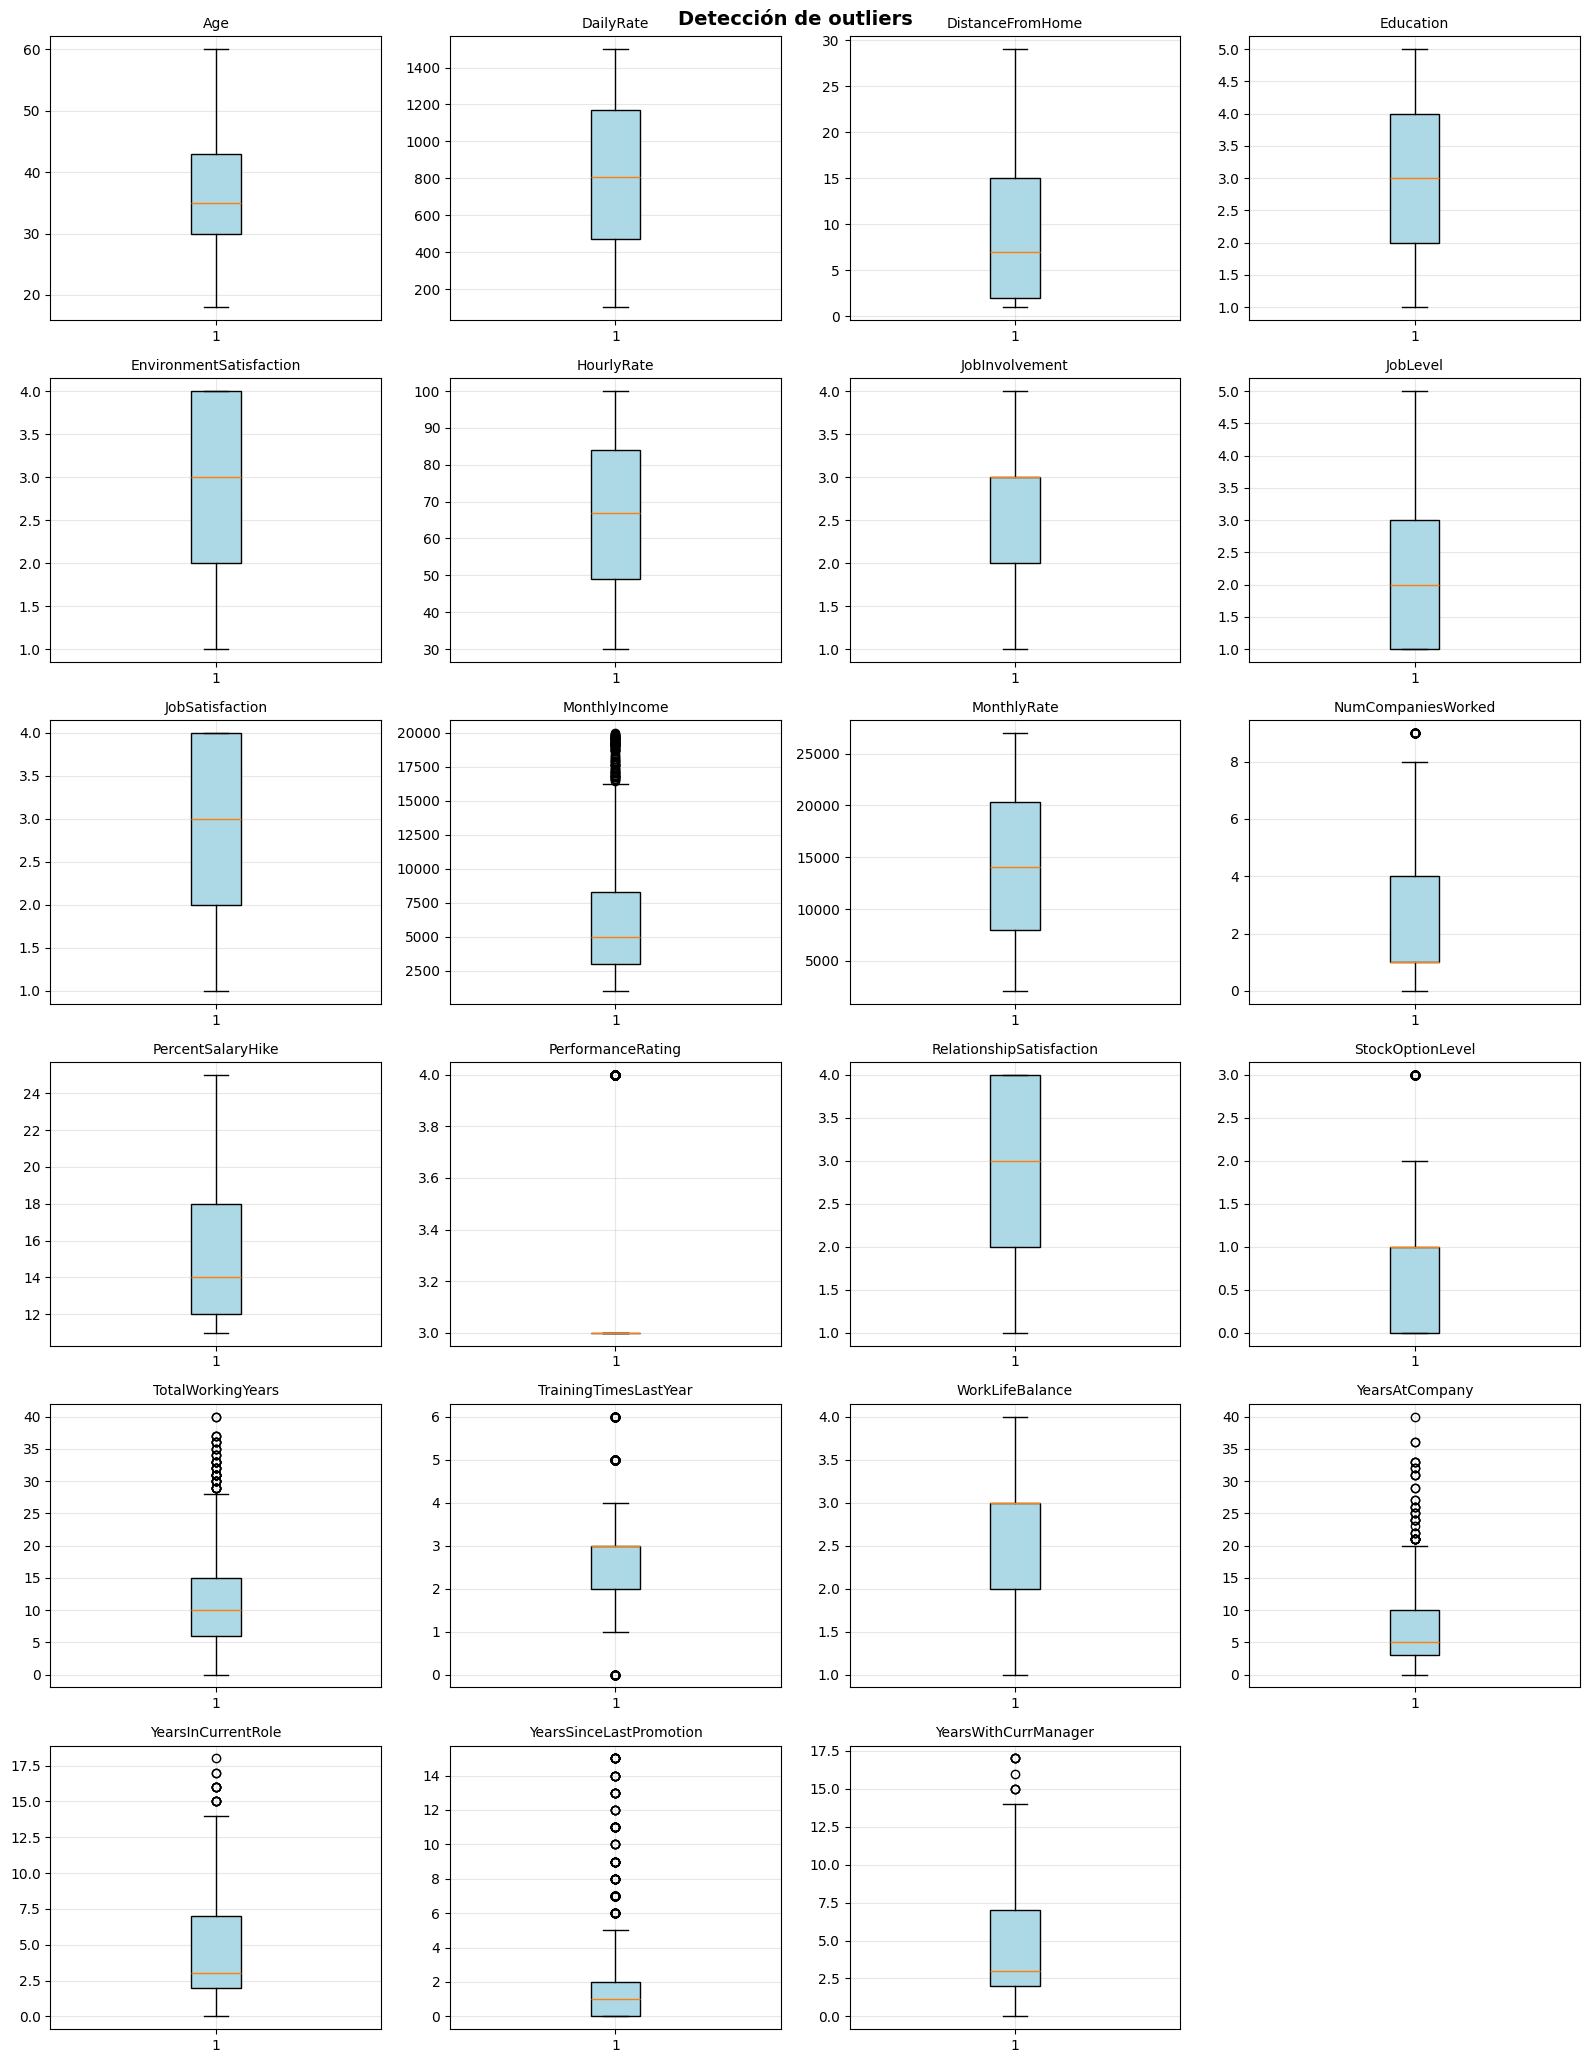

In [16]:
# Outliers

fig, axes = plt.subplots(n_rows_plot, n_cols_plot, figsize=(16, 3.5 * n_rows_plot))
axes = axes.ravel()

for col, ax in zip(num_cols_Xtrain, axes):
    ax.boxplot(Xtrain[col].dropna(),
               vert=True,
               patch_artist=True,
               boxprops=dict(facecolor='lightblue'))
    ax.set_title(col, fontsize=10)
    ax.grid(alpha=0.3)

for idx in range(len(num_cols_Xtrain), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Detección de outliers', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [17]:
# Cardinalidad

cat_info = pd.DataFrame([
    {'variable': col,
     'n_categorias': Xtrain[col].nunique(),
     'categoria_dominante': Xtrain[col].mode()[0],
     '%_dominante': round(100 * Xtrain[col].value_counts(normalize=True).iloc[0], 2)}
    for col in cat_cols_Xtrain
]).sort_values('n_categorias', ascending=False)
print(cat_info)

         variable  n_categorias     categoria_dominante  %_dominante
4         JobRole             9         Sales Executive        23.52
2  EducationField             6           Life Sciences        42.86
0  BusinessTravel             3           Travel_Rarely        70.94
1      Department             3  Research & Development        64.53
5   MaritalStatus             3                 Married        46.36
3          Gender             2                    Male        58.99
6        OverTime             2                      No        71.72


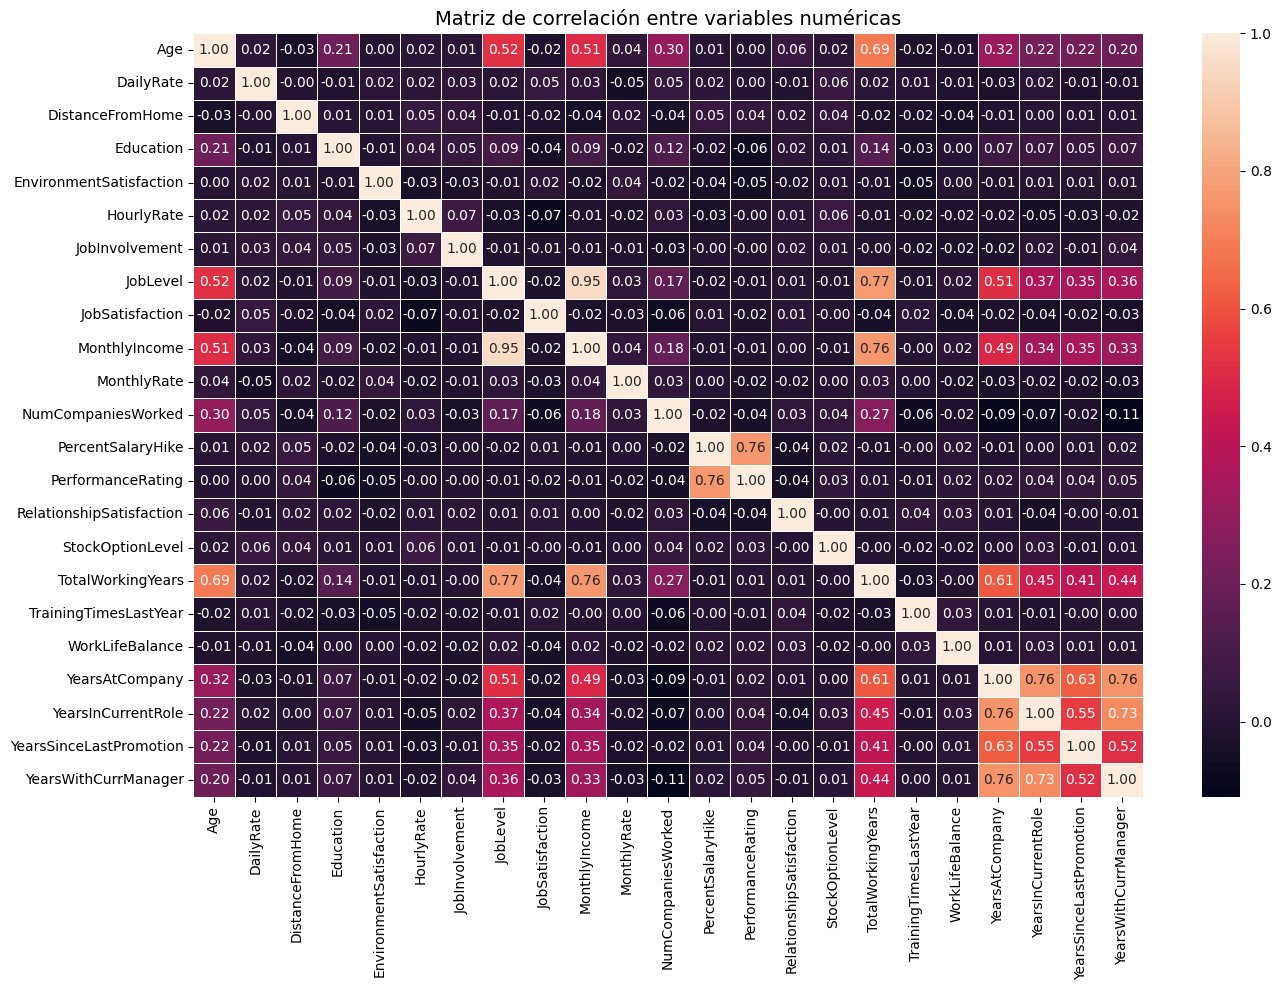


Pares con correlación > 0.7:
  JobLevel - MonthlyIncome: 0.95
  PercentSalaryHike - PerformanceRating: 0.76
  JobLevel - TotalWorkingYears: 0.77
  MonthlyIncome - TotalWorkingYears: 0.76
  YearsAtCompany - YearsInCurrentRole: 0.76
  YearsAtCompany - YearsWithCurrManager: 0.76
  YearsInCurrentRole - YearsWithCurrManager: 0.73


In [18]:
# Multicolinealidad

plt.figure(figsize=(14, 10))
corr = Xtrain[num_cols_Xtrain].corr()
sns.heatmap(corr,
            annot=True,
            fmt='.2f',
            linewidths=0.5)
plt.title('Matriz de correlación entre variables numéricas', fontsize=14)
plt.tight_layout()
plt.show()

correlation_threshold = 0.7
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
print(f"\nPares con correlación > {correlation_threshold}:")
for col in upper.columns:
    for idx in upper.index:
        if pd.notna(upper.loc[idx, col]) and abs(upper.loc[idx, col]) > correlation_threshold:
            print(f"  {idx} - {col}: {upper.loc[idx, col]:.2f}")

In [19]:
# Dataset de train para análisis bivariado (variables vs Attrition)
data_train = pd.concat([Xtrain, ytrainT], axis=1)

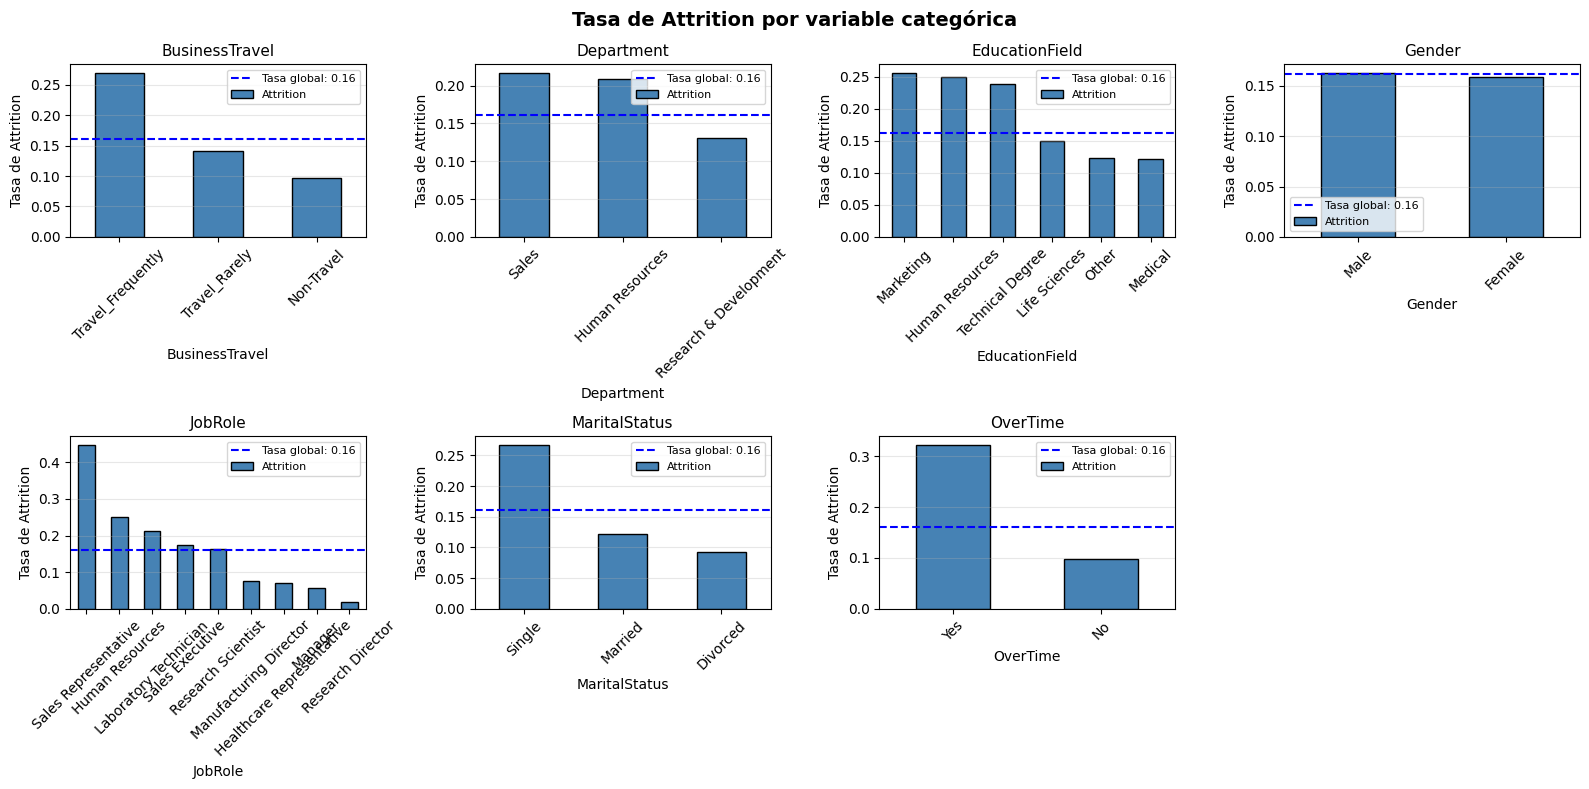

In [20]:
# Tasa de Attrition por variable categórica
n_cat = len(cat_cols_Xtrain)
n_rows_cat = int(np.ceil(n_cat / 4))

fig, axes = plt.subplots(n_rows_cat, 4, figsize=(16, 4 * n_rows_cat))
axes = axes.ravel()

tasa_global = data_train['Attrition'].mean()

for col, ax in zip(cat_cols_Xtrain, axes):
    tasa = data_train.groupby(col)['Attrition'].mean().sort_values(ascending=False)
    tasa.plot(kind='bar', ax=ax, color='steelblue', edgecolor='black')
    ax.axhline(tasa_global, color='blue', linestyle='--',
               label=f'Tasa global: {tasa_global:.2f}')
    ax.set_title(col, fontsize=11)
    ax.set_ylabel('Tasa de Attrition')
    ax.tick_params(axis='x', rotation=45)
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)

for idx in range(len(cat_cols_Xtrain), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Tasa de Attrition por variable categórica', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

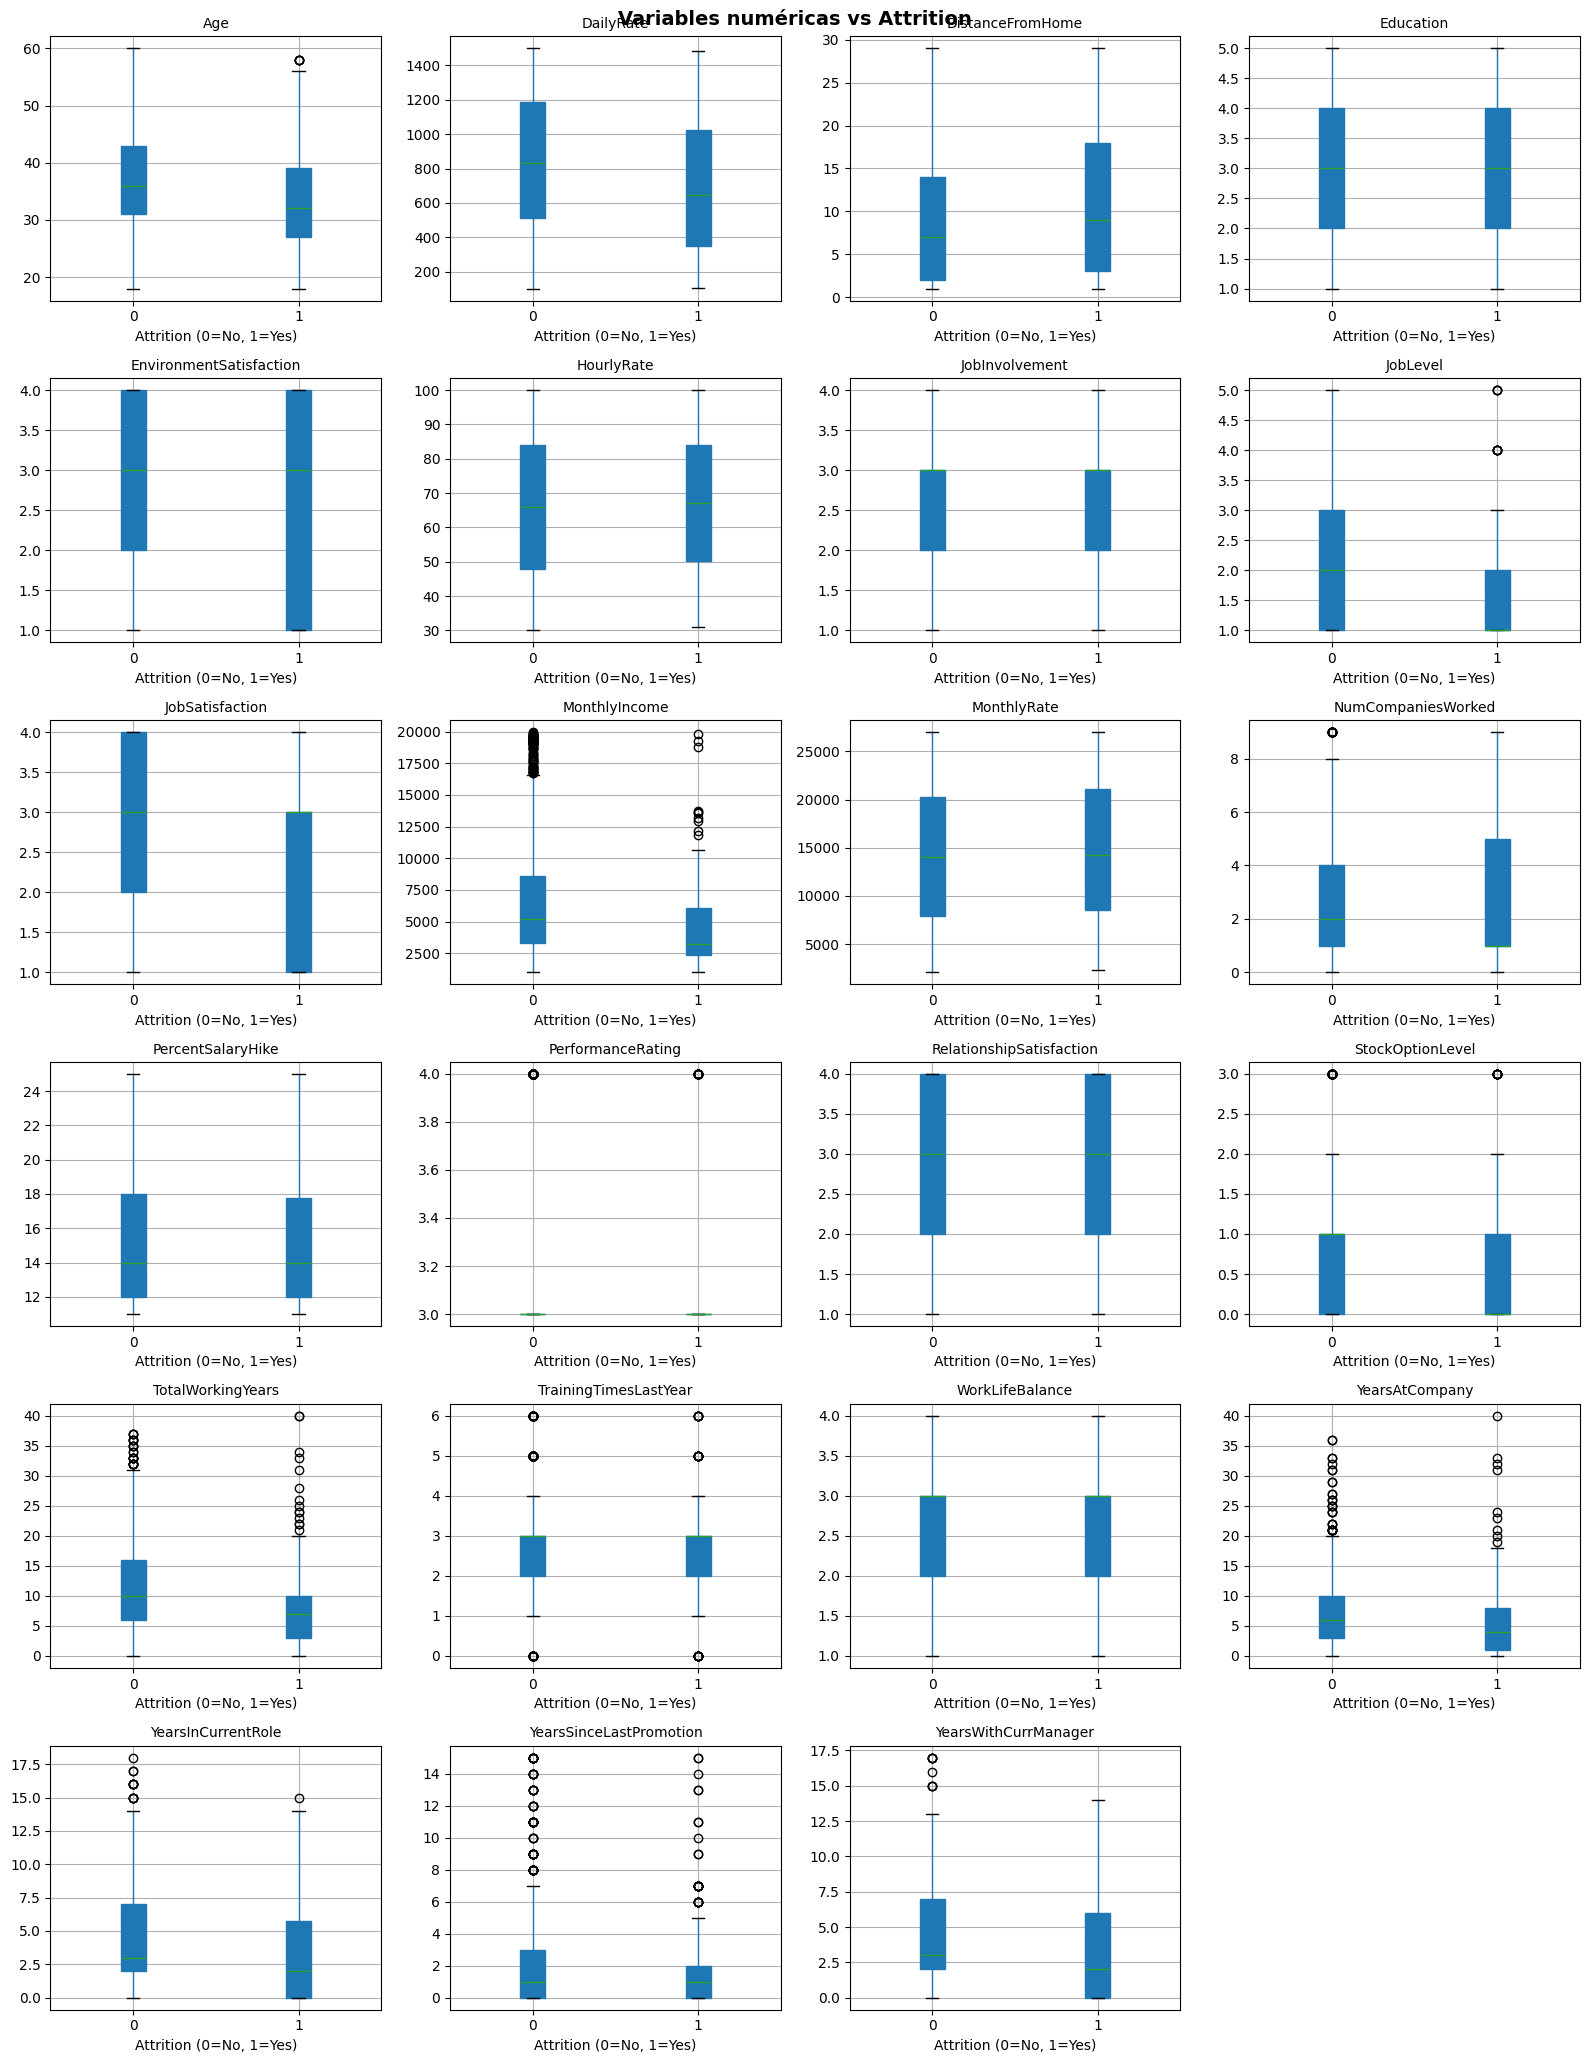

In [21]:
# Variables numéricas vs Attrition
fig, axes = plt.subplots(n_rows_plot, n_cols_plot, figsize=(16, 3.5 * n_rows_plot))
axes = axes.ravel()

for col, ax in zip(num_cols_Xtrain, axes):
    data_train.boxplot(column=col, by='Attrition', ax=ax, patch_artist=True)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('Attrition (0=No, 1=Yes)')

for idx in range(len(num_cols_Xtrain), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Variables numéricas vs Attrition', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
